In [ ]:
import os 
import numpy as np 
import pandas as pd 
# import scipy.stats as stats
# from scipy.stats import pearsonr 
import matplotlib.pyplot as plt 
# import seaborn as sns 
import tarfile
import tqdm

In [2]:
# base_dir = "/lustre/nvwulf/home/ronsharma/tcga-brca"

# manifest = pd.read_csv(os.path.join(base_dir, "gdcmanifest.txt"), sep="\t")

# expression = None

# for _, row in manifest.iterrows():

#     filename = row["filename"]
#     file_id = row["id"]          

#     path = os.path.join(base_dir, file_id, filename)

#     df = pd.read_csv(path, sep="\t", skiprows=1, index_col=0)
#     df = df.iloc[4:]
#     df = df.loc[:, ["tpm_unstranded"]]

#     patient = filename.split(".")[0] 
#     df = df.rename(columns={"tpm_unstranded": patient})

#     if expression is None:
#         expression = df
#     else:
#         expression = expression.merge(df, on="gene_id")

In [3]:
# base_dir = "/lustre/nvwulf/home/ronsharma/tcga-brca"

# manifest = pd.read_csv(os.path.join(base_dir, "gdcmanifest.txt"), sep="\t")
# print(len(manifest))
# dfs = []

# for _, row in tqdm.tqdm(manifest.iterrows()):
#     filename = row["filename"]
#     file_id = row["id"]

#     path = os.path.join(base_dir, file_id, filename)

#     df = pd.read_csv(
#         path,
#         sep="\t",
#         skiprows=1,
#         index_col=0,
#         usecols=["gene_id", "tpm_unstranded"]
#     )

#     df = df.iloc[4:]

#     patient = filename.split(".")[0]

#     df.columns = [patient]

#     dfs.append(df)
#     # print(dfs)
#     break

# expression = pd.concat(dfs, axis=1)

In [4]:
# import pandas as pd
# import os
# import tqdm

# base_dir = "/lustre/nvwulf/home/ronsharma/tcga-brca"
# manifest = pd.read_csv(os.path.join(base_dir, "gdcmanifest.txt"), sep="\t")

# expression_dict = {}
# gene_ids = None

# for _, row in tqdm.tqdm(manifest.iterrows(), total=len(manifest)):
#     filename = row["filename"]
#     file_id = row["id"]

#     path = os.path.join(base_dir, file_id, filename)

#     df = pd.read_csv(path, sep="\t", skiprows=1)

#     df = df.iloc[4:]
#     df = df[df["gene_type"] == "protein_coding"]

#     if gene_ids is None:
#         gene_ids = df["gene_id"]

#     patient = filename.split(".")[0]
#     expression_dict[patient] = df["tpm_unstranded"].values

# expression = pd.DataFrame(expression_dict)
# expression.insert(0, "gene_id", gene_ids.values)

In [ ]:
basic_dir = "/lustre/nvwulf/home/ronsharma/breaststuff"
# expression.to_csv(os.path.join(basic_dir, "coding_expr.csv"))

In [8]:
expr = pd.read_csv(os.path.join(basic_dir, "expression_matrix.csv"), index_col=0)

FileNotFoundError: [Errno 2] No such file or directory: '/lustre/nvwulf/home/ronsharma/breaststuff/expression_matrix.csv'

In [7]:
with tarfile.open("/lustre/nvwulf/home/ronsharma/clinical.project-tcga-brca.2026-07-02.tar.gz", "r:gz") as tar:
    print(tar.getnames())
    file_content = tar.extractfile("clinical.tsv").read().decode('utf-8')

['clinical.tsv', 'family_history.tsv', 'exposure.tsv', 'pathology_detail.tsv', 'follow_up.tsv']


In [1]:
import sys
print(sys.version)

3.9.25 (main, Nov 10 2025, 00:00:00) 
[GCC 11.5.0 20240719 (Red Hat 11.5.0-11)]


In [8]:
from io import StringIO

clinical = pd.read_csv(StringIO(file_content), sep="\t")

/tmp/ipykernel_4087760/4030025924.py:3: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  clinical = pd.read_csv(StringIO(file_content), sep="\t")


In [9]:
count = 0
for x in clinical["diagnoses.ajcc_pathologic_stage"]:
    count+=1
    if x == "'--":
        continue
    else:
        print(x)
print(count)

Stage IA
Stage IA
Stage IA
Stage I
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIA
Stage IIA
Stage IIA
Stage 0
Stage 0
Stage 0
Stage IA
Stage IA
Stage IA
Stage IA
Stage IA
Stage IA
Stage IA
Stage IIIA
Stage IIIA
Stage IIIA
Stage IIIA
Stage IIIA
Stage IV
Stage IV
Stage IV
Stage IV
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IB
Stage IB
Stage IB
Stage IIIA
Stage IIIA
Stage IIIA
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIB
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIIC
Stage IIIC
Stage IIIC
Stage IIIC
Stage IIIC
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIIA
Stage IIIA
Stage IIIA
Stage IIIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage IIA
Stage I
Stage I
Stage I
Stage I
Stage I
Stage I
Stage IIB
Stage IIB
Stage IIB
Stage IIIA

In [10]:
import json

with open("/lustre/nvwulf/home/ronsharma/metadata_brca.json", "r") as f:
    metadata = json.load(f)

In [11]:
meta_case_ids = set()
matchids = {}

for item in metadata:
    try:
        case_id = item["associated_entities"][0]["case_id"]
        meta_case_ids.add(case_id)
        matchids[case_id] = item["file_name"]
    except:
        continue

len(meta_case_ids)

1455

In [12]:
for col in expr.columns:
    print(col)

94027f46-390c-4dda-ab89-cb1ac0a291cd
df45fb41-4511-4dab-b865-fcdfcda0400a
c33ecc28-d5ba-4416-b93d-445b7883b6e8
602e3d24-a45d-4fe4-9b70-a679d93f470d
03d891b3-8faf-4384-94ce-2015f1ca5df0
f8ff90c6-3554-4e19-ae56-18f30f51f9b5
4c6cb929-293d-452e-b7f8-d535b48cf073
a8e0466b-d106-44b7-b846-c4fb666715f5
eb44c266-8b8f-4012-ad67-f4ac40698391
2dd0b954-db3e-402d-9c06-6160e199dedb
5cc4350c-416e-4f2c-be73-12af68ad1ee4
7c9a2493-5667-48ec-8998-81e13722b4ab
c2e73efe-8112-48fc-9dbd-29b4b5b89ad0
28f1b708-bd3c-4ae7-935f-3282f75304a7
2c1b1cbb-6e9f-4416-8faa-abb31d6b4e0e
9da89066-8d82-4ace-80e1-889d3c73c8eb
fb49b14e-d40f-4270-98b3-458ce60f2cde
3f32cdec-5a60-4147-b313-7c9a9dfefc78
36125e17-48fd-4eea-874c-ed2e2e218402
6798cbfe-7aca-4f33-b4fc-162bf579a303
ecdac97e-eec5-4753-a572-8aff707178e5
f2dda955-5a39-43c1-93a2-83953b2b91d1
e7c2b898-cd11-42a1-b309-b4de1ab01965
3d05d072-d042-4c02-aaf6-ee2e589003d6
bb06ad3a-4d73-4f88-8f3c-954dce2b38ef
c1f95e8e-aaaa-4090-8f64-c619aa543d1b
707fad7d-f284-456a-abfa-17289b40579f
7

In [13]:
clinical_case_ids = set(clinical["cases.case_id"].dropna())

In [14]:
case_ids = clinical["cases.case_id"].dropna()

duplicates = case_ids.value_counts()
duplicates = duplicates[duplicates > 1]

print(f"Number of unique duplicated case IDs: {len(duplicates)}")
print(duplicates)

Number of unique duplicated case IDs: 1030
cases.case_id
c07b122e-ac50-4db2-add2-5617a5d0e976    40
ccd4a24b-d8cc-4686-9dee-c98b0c5a8d21    33
a8e7d8a4-bbf0-496b-b387-8e014cfdcea6    22
deba32e4-0e68-4711-941b-3b63bd965afb    21
8d5fe6e8-d2cc-481f-a6a1-9cb6e7982cde    20
                                        ..
cb9f5e50-f49d-4899-8895-9367afcc1015     2
a5b44d66-c162-46b5-9df2-86305f0385c5     2
3efa245d-177d-4ef9-94f7-f554c54e345e     2
c462e422-eb8d-4daf-9897-2a9c6cbd783a     2
0ed9ad26-7fdc-4d75-93f9-d029eee94993     2
Name: count, Length: 1030, dtype: int64


In [15]:
len(list(clinical["cases.case_id"].dropna())) - sum(duplicates)

68

In [16]:
matches = meta_case_ids.intersection(clinical_case_ids)

print("Metadata case_ids:", len(meta_case_ids))
print("Clinical case_ids:", len(clinical_case_ids))
print("Matched case_ids:", len(matches))

Metadata case_ids: 1455
Clinical case_ids: 1098
Matched case_ids: 1095


In [17]:
fileidmatch = {}
for match in matches:
    if match in matchids:
        fileidmatch[match] = matchids[match].split(".")[0]

In [18]:
countiv = 0
types = set()
filewithstages = {}
for case_id, stage in clinical[["cases.case_id", "diagnoses.ajcc_pathologic_stage"]].values:
    if case_id in fileidmatch:
        file_name = fileidmatch[case_id]
        # print(f"Case ID: {case_id}, Stage: {stage}, File Name: {file_name}")
        types.add(stage)
        if stage == "Stage IV":
            countiv += 1
        if stage != "'--" and stage != "Stage X":
            filewithstages[case_id] = file_name
print(f"Total Stage IV cases: {countiv}")
print(f"Unique stages: {types}")

Total Stage IV cases: 77
Unique stages: {'Stage X', 'Stage IIIA', 'Stage 0is', 'Stage IIA', 'Stage I', 'Stage IA', 'Stage IIIB', 'Stage IIIC', "'--", 'Stage 0', 'Stage III', 'Stage IB', 'Stage IV', 'Stage IIB', 'Stage II'}


In [19]:
print("Total rows:", len(clinical))

print("Unique case_ids:",
      clinical["cases.case_id"].nunique())

print("Unique valid case_ids:",
      clinical.loc[
          (~clinical["diagnoses.ajcc_pathologic_stage"].isin(["'--", "Stage X"])),
          "cases.case_id"
      ].nunique())

print("Unique valid case_ids overlapping:", len(filewithstages))

Total rows: 5546
Unique case_ids: 1098
Unique valid case_ids: 1074
Unique valid case_ids overlapping: 1071


In [20]:
# Total number of duplicated index entries (excluding the first occurrence)
num_duplicates = expr.index.duplicated().sum()

print(f"Number of duplicated index entries: {num_duplicates}")

Number of duplicated index entries: 0


In [21]:
from collections import defaultdict
import pandas as pd

patient_stages = defaultdict(set)

for case_id, stage in clinical[["cases.case_id", "diagnoses.ajcc_pathologic_stage"]].values:

    if stage in ["'--", "Stage X"]:
        continue

    patient_stages[case_id].add(stage)

duplicate_patients = {
    case_id
    for case_id, stages in patient_stages.items()
    if len(stages) > 1
}

print(f"Patients with conflicting stages: {len(duplicate_patients)}")

Patients with conflicting stages: 20


In [22]:
labels = {}
typecount = {}

for case_id, stage in clinical[
    ["cases.case_id", "diagnoses.ajcc_pathologic_stage"]
].values:

    if case_id in duplicate_patients:
        continue

    if stage in ["'--", "Stage X"]:
        continue

    if case_id not in filewithstages:
        continue

    sample = filewithstages[case_id]

    if sample not in expr.columns:
        continue

    if sample not in labels:
        if stage not in typecount:
            typecount[stage] = 0
        typecount[stage] += 1
        
    labels[sample] = 1 if stage == "Stage IV" or stage == "Stage IIIC" else 0
print(f"Labeled samples: {len(labels)}")

Labeled samples: 1051


In [23]:
labelsiv = {}
typecount = {}

for case_id, stage in clinical[
    ["cases.case_id", "diagnoses.ajcc_pathologic_stage"]
].values:

    if case_id in duplicate_patients:
        continue

    if stage in ["'--", "Stage X"]:
        continue

    if case_id not in filewithstages:
        continue

    sample = filewithstages[case_id]

    if sample not in expr.columns:
        continue

    if sample not in labelsiv:
        if stage not in typecount:
            typecount[stage] = 0
        typecount[stage] += 1
        
    labelsiv[sample] = 1 if stage == "Stage IV" else 0
print(f"Labeled samples: {len(labelsiv)}")

Labeled samples: 1051


In [24]:
for type in types:
    count = sum(1 for stage in clinical["diagnoses.ajcc_pathologic_stage"] if stage == type)
    print(f"Count of {type}: {count}")

Count of Stage X: 42
Count of Stage IIIA: 795
Count of Stage 0is: 3
Count of Stage IIA: 1566
Count of Stage I: 353
Count of Stage IA: 349
Count of Stage IIIB: 89
Count of Stage IIIC: 364
Count of '--: 568
Count of Stage 0: 12
Count of Stage III: 14
Count of Stage IB: 33
Count of Stage IV: 77
Count of Stage IIB: 1254
Count of Stage II: 27


In [25]:
expr = expr.loc[:, expr.columns.isin(labelsiv)]

In [26]:
yiv = pd.Series(labelsiv).loc[expr.columns]

print(expr.shape)
print(yiv.shape)

print(yiv.value_counts())

(60660, 1051)
(1051,)
0    1032
1      19
Name: count, dtype: int64


In [27]:
y = pd.Series(labels).loc[expr.columns]

print(expr.shape)
print(y.shape)

print(y.value_counts())

(60660, 1051)
(1051,)
0    969
1     82
Name: count, dtype: int64


In [28]:
X = expr.T

In [29]:
# y = y.astype(np.float32)
yiv = yiv.astype(np.float32)

In [ ]:
# X.to_csv(os.path.join(basic_dir, "X.csv"))
# y.to_csv(os.path.join(basic_dir, "y.csv"), index=False)

In [31]:
yiv.to_csv(os.path.join(basic_dir, "yiv.csv"), index=False)

In [32]:
X.shape

(1051, 60660)

In [ ]:
X = pd.read_csv(os.path.join(basic_dir, "X.csv"), index_col=0)
yiv = pd.read_csv(os.path.join(basic_dir, "yiv.csv"), index_col=0)

: 

In [ ]:
X.shape

In [10]:
keep = (X > 1).sum(axis=0) >= 0.2 * len(X)
X = X.loc[:, keep]

In [11]:
from sklearn.feature_selection import VarianceThreshold

vt = VarianceThreshold(0)
X = pd.DataFrame(
    vt.fit_transform(X),
    index=X.index,
    columns=X.columns[vt.get_support()]
)

In [12]:
X = np.log2(X + 1)

In [36]:
# from sklearn.model_selection import train_test_split

# X_train_val, X_test, y_train_val, y_test = train_test_split(
#     X,
#     y,
#     stratify=y,
#     test_size=0.2,
#     random_state=42
# )

In [ ]:
from sklearn.model_selection import train_test_split

X_train_valiv, X_testiv, y_train_valiv, y_testiv = train_test_split(
    X,
    yiv,
    stratify=yiv,
    test_size=0.2,
    random_state=42,
)

ValueError: With n_samples=0, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [14]:
from tqdm import trange
from sklearn.linear_model import ElasticNet
import numpy as np
from sklearn.metrics import mean_squared_error
import os

# Parameters
alpha = 0.001
l1_ratio = 0.5
n_trials = 100

# Initialize feature selection count
coefficients_index = np.zeros(len(X_train_valiv.columns))

for i in trange(n_trials):
    # Initialize Elastic Net model
    model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=i, max_iter=10000)

    # Fit on training data
    model.fit(X_train_valiv, y_train_valiv)

    # Count non-zero coefficients
    nonzero_indices = np.where(np.abs(model.coef_) > 0.1)[0]
    coefficients_index[nonzero_indices] += 1

    # Predict on test set
    y_pred = model.predict(X_testiv)
    mse = mean_squared_error(y_testiv, y_pred)
    # print(f"Trial {i} MSE: {mse}")

# Save feature selection counts
with open(os.path.join(basic_dir, 'sf01.txt'), 'w') as file:
    for item in coefficients_index:
        file.write(f"{item}\n")

NameError: name 'X_train_valiv' is not defined

In [39]:
# X.to_csv(os.path.join(basic_dir, "X.csv"))

In [40]:
# y.to_csv(os.path.join(basic_dir, "y.csv"), index=False)

In [88]:
import numpy as np

with open(os.path.join(basic_dir, 'selected_features.txt'), 'r') as file:
    coefficients_index = np.array([float(line.strip()) for line in file])

In [89]:
n_trials = 100
threshold = 0.8
selected_feature_index = np.where(coefficients_index >= (threshold*n_trials))[0]

In [90]:
X_train_valiv = X_train_valiv.iloc[:, selected_feature_index]
X_testiv = X_testiv.iloc[:, selected_feature_index]
# X_train_val = X_train_val.iloc[:, selected_feature_index]
# X_test = X_test.iloc[:, selected_feature_index]

In [91]:
X_testiv.shape

(211, 777)

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler


def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": specificity,
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_score),
        "PR AUC": average_precision_score(y_test, y_score),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Confusion Matrix": confusion_matrix(y_test, y_pred, labels=[0,1]),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


def cross_validate_model(model_factory, X_data, y_data, cv):
    fold_results = []
    best_model = None
    best_recall = -1

    for fold, (train_idx, test_idx) in enumerate(cv.split(X_data, y_data), start=1):
        X_train = X_data.iloc[train_idx] if hasattr(X_data, "iloc") else X_data[train_idx]
        X_test = X_data.iloc[test_idx] if hasattr(X_data, "iloc") else X_data[test_idx]
        y_train = y_data.iloc[train_idx] if hasattr(y_data, "iloc") else y_data[train_idx]
        y_test = y_data.iloc[test_idx] if hasattr(y_data, "iloc") else y_data[test_idx]
        # print(y_data.value_counts())
        # print(y_test.value_counts())
        model = model_factory()
        model.fit(X_train, y_train)

        fold_result = evaluate_model(model, X_test, y_test)
        fold_result["Fold"] = fold
        fold_results.append(fold_result)
        if fold_result["Recall"] > best_recall:
            best_recall = fold_result["Recall"]
            best_model = model

    return pd.DataFrame(fold_results), best_model

In [46]:
# from sklearn.pipeline import Pipeline
# from sklearn.feature_selection import SelectFromModel
# from sklearn.linear_model import ElasticNet, LogisticRegression
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.preprocessing import StandardScaler


# logreg = Pipeline([
#     (
#         "feature_selection",
#         SelectFromModel(
#             ElasticNet(
#                 alpha=0.001,
#                 l1_ratio=0.5,
#                 max_iter=10000,
#                 random_state=42
#             )
#         )
#     ),

#     (
#         "scaler",
#         StandardScaler()
#     ),

#     (
#         "classifier",
#         LogisticRegression(
#             class_weight="balanced",
#             max_iter=5000
#         )
#     )
# ])

# rfr = Pipeline([
#     (
#         "feature_selection",
#         SelectFromModel(
#             ElasticNet(
#                 alpha=0.001,
#                 l1_ratio=0.5,
#                 max_iter=10000,
#                 random_state=42
#             )
#         )
#     ),

#     (
#         "classifier",
#         RandomForestClassifier(
#             class_weight="balanced",
#             n_estimators=100,
#             random_state=42
#         )
#     )
# ])

# sgd = Pipeline([
#     (
#         "feature_selection",
#         SelectFromModel(
#             ElasticNet(
#                 alpha=0.001,
#                 l1_ratio=0.5,
#                 max_iter=10000,
#                 random_state=42
#             )
#         )
#     ),

#     (
#         "scaler",
#         StandardScaler()
#     ),

#     (
#         "classifier",
#         SGDClassifier(
#             loss="log_loss",
#             class_weight="balanced",
#             max_iter=5000,
#             random_state=42
#         )
#     )
# ])

# svm = Pipeline([
#     (
#         "feature_selection",
#         SelectFromModel(
#             ElasticNet(
#                 alpha=0.001,
#                 l1_ratio=0.5,
#                 max_iter=10000,
#                 random_state=42
#             )
#         )
#     ),

#     (
#         "scaler",
#         StandardScaler()
#     ),

#     (
#         "classifier",
#         LinearSVC(
#             class_weight="balanced",
#             max_iter=5000,
#             random_state=42
#         )
#     )
# ])

In [47]:
from sklearn.svm import LinearSVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_factories = {
    "Logistic Regression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000, class_weight="balanced")
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
    ),
    "SGDClassifier": lambda: make_pipeline(
        StandardScaler(),
        SGDClassifier(
            loss="log_loss",
            penalty="elasticnet",
            alpha=0.0001,
            l1_ratio=0.15,
            max_iter=1000,
            random_state=42,
        )
    ),
    "Linear SVM": lambda: make_pipeline(
        StandardScaler(),
        LinearSVC(
            class_weight="balanced",
            random_state=42,
            max_iter=10000,
        )
    ),
}

cv_resultsiv = {}
trained_modelsiv = {}
evaluate_modelsiv = {}

for name, factory in model_factories.items():
    fold_resultsiv, best_model = cross_validate_model(factory, X_train_valiv, y_train_valiv, cv)
    cv_resultsiv[name] = fold_resultsiv
    # trained_modelsiv[name] = factory().fit(X_train_valiv, y_train_valiv)
    evaluate_modelsiv[name] = evaluate_model(best_model, X_testiv, y_testiv)
    print(f"=== {name} ===")
    print(
        fold_resultsiv[
            [
                "Fold",
                "Accuracy",
                "Precision",
                "Recall",
                "Specificity",
                "F1",
                "ROC AUC",
                "PR AUC",
                "Balanced Accuracy",
                "MCC",
            ]
        ]
    )
    print("Mean metrics:")
    print(fold_resultsiv.drop(columns=["Fold", "Confusion Matrix"]).mean(numeric_only=True))
    print()

cv_summary = pd.concat(
    [result.assign(Model=name) for name, result in cv_resultsiv.items()],
    ignore_index=True,
)

=== Logistic Regression ===
   Fold  Accuracy  Precision    Recall  Specificity   F1  ROC AUC  PR AUC  \
0     1  0.982143        0.0  0.000000          1.0  0.0      1.0     1.0   
1     2  1.000000        1.0  1.000000          1.0  1.0      1.0     1.0   
2     3  0.994048        1.0  0.666667          1.0  0.8      1.0     1.0   
3     4  1.000000        1.0  1.000000          1.0  1.0      1.0     1.0   
4     5  0.988095        1.0  0.333333          1.0  0.5      1.0     1.0   

   Balanced Accuracy       MCC  
0           0.500000  0.000000  
1           1.000000  1.000000  
2           0.833333  0.814034  
3           1.000000  1.000000  
4           0.666667  0.573883  
Mean metrics:
Accuracy               0.992857
Precision              0.800000
Recall                 0.600000
Specificity            1.000000
F1                     0.660000
ROC AUC                1.000000
PR AUC                 1.000000
Balanced Accuracy      0.800000
MCC                    0.677583
TN       

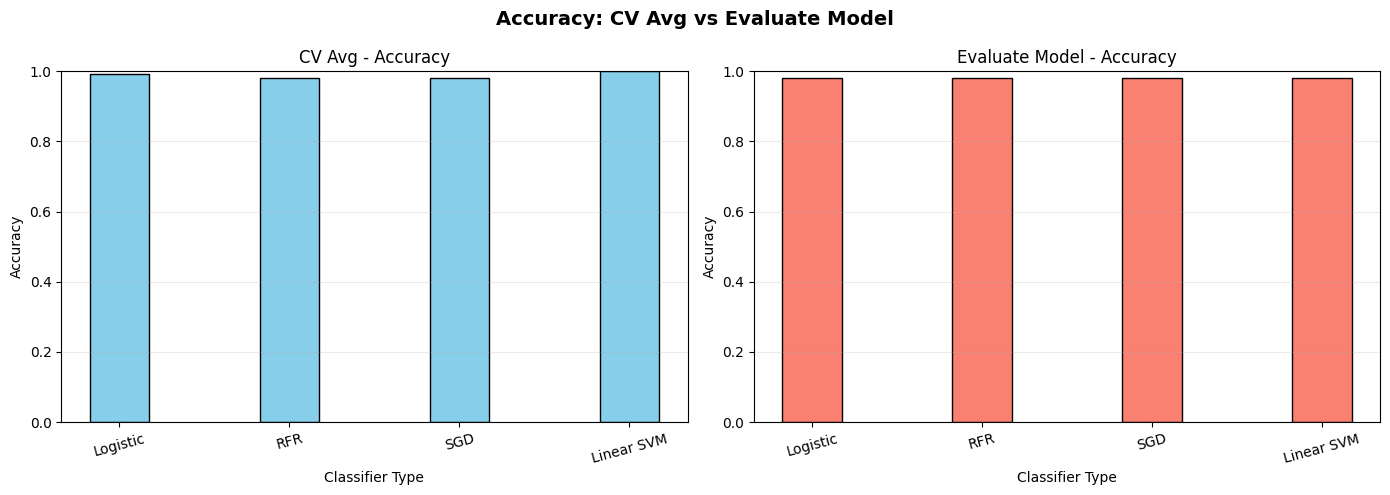

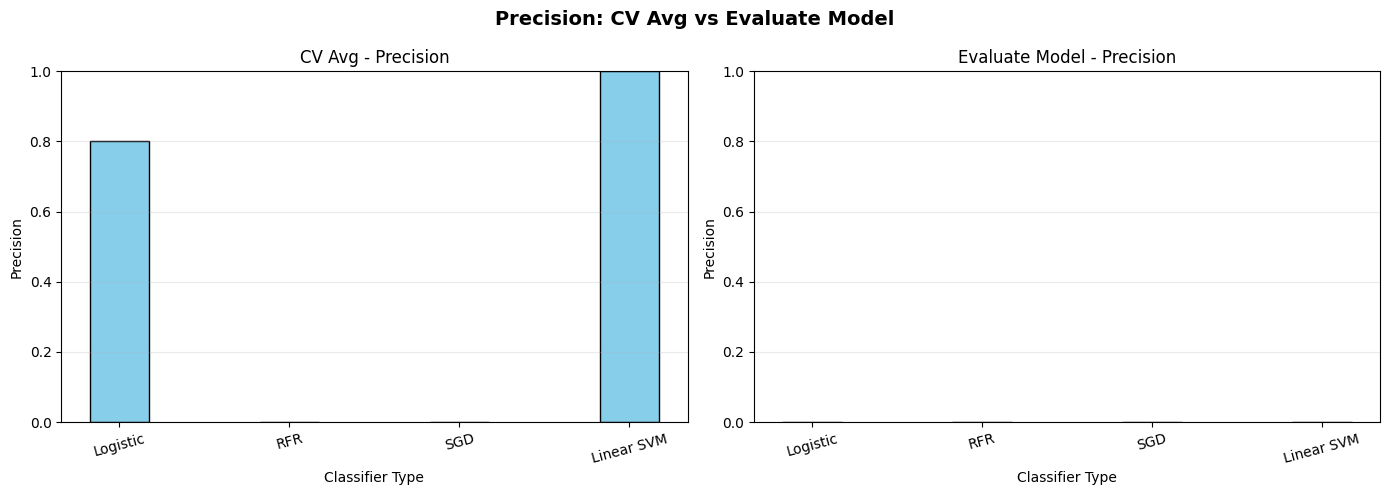

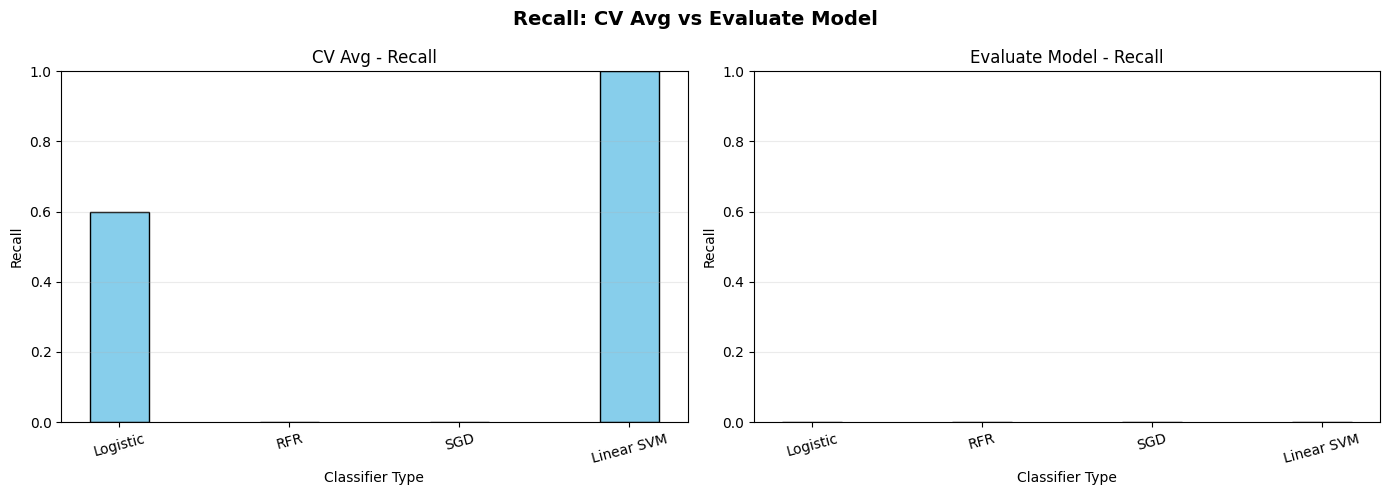

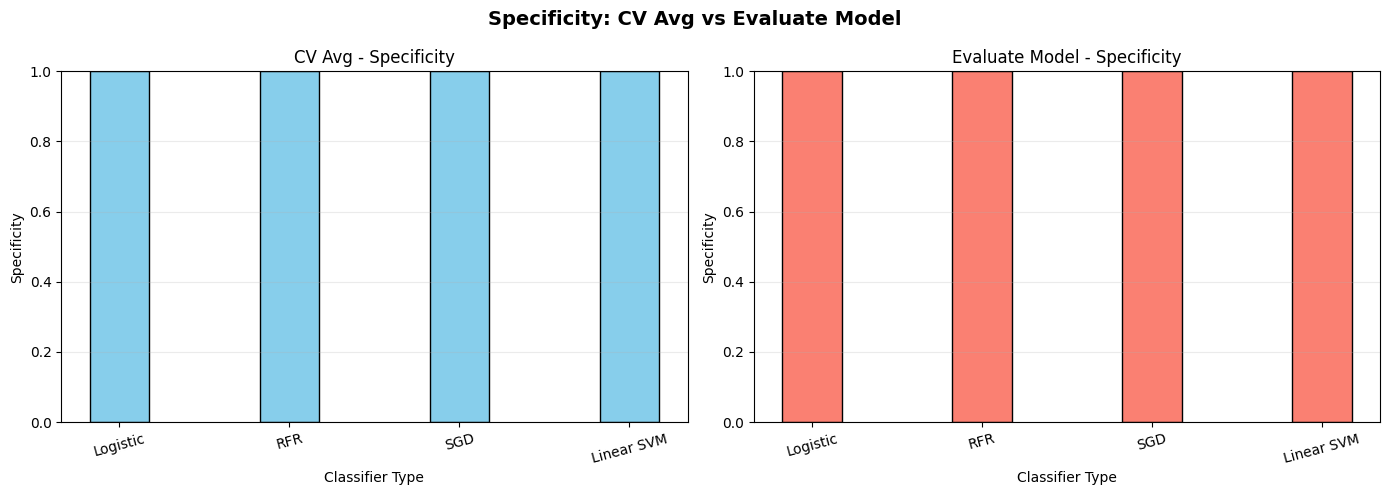

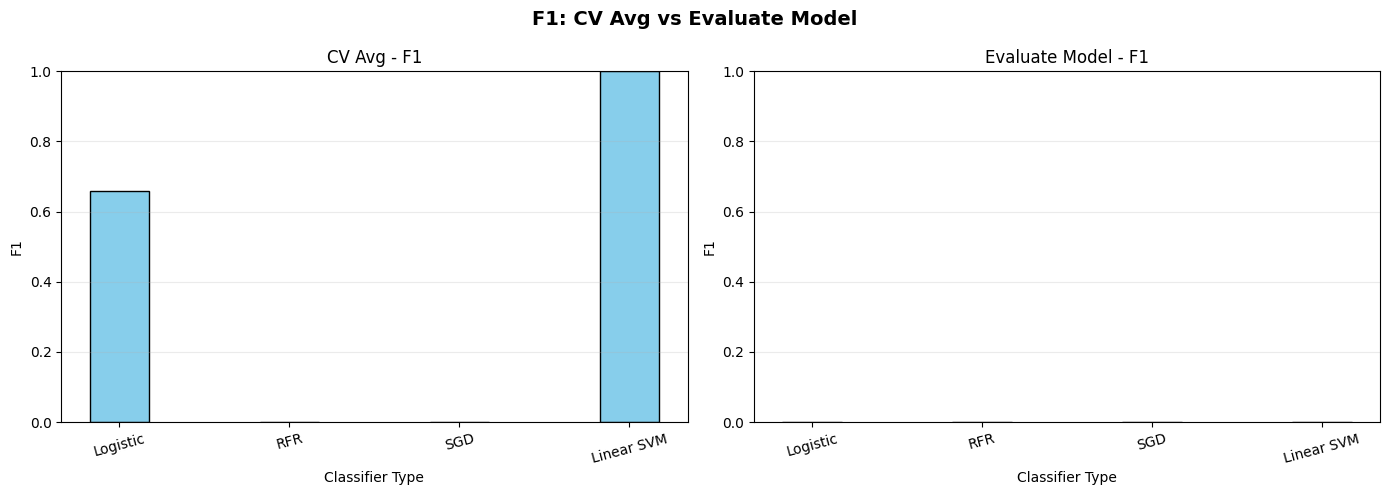

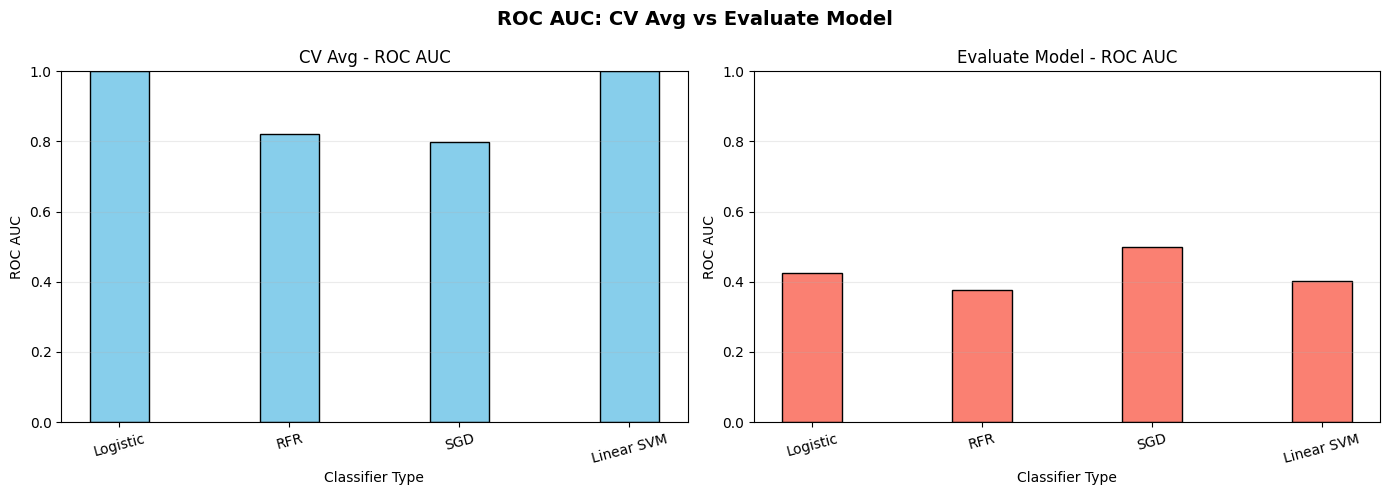

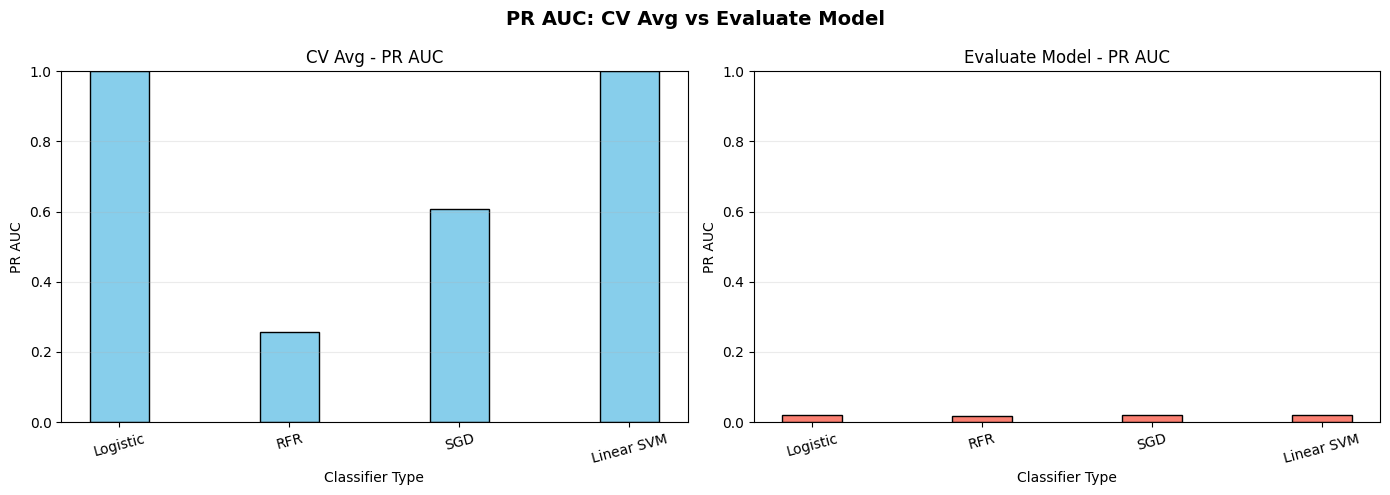

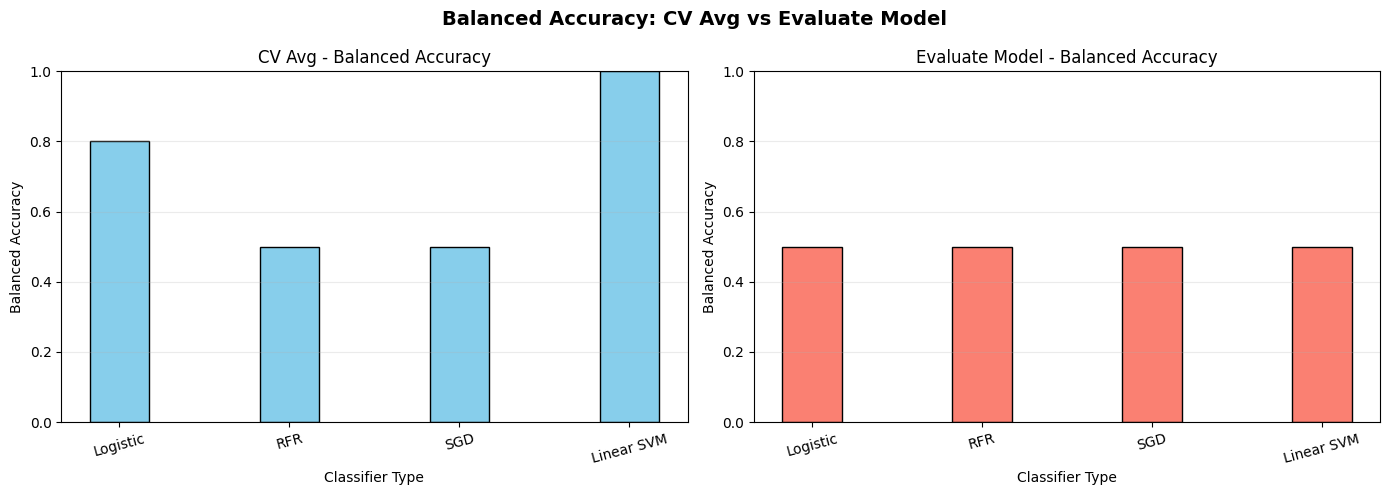

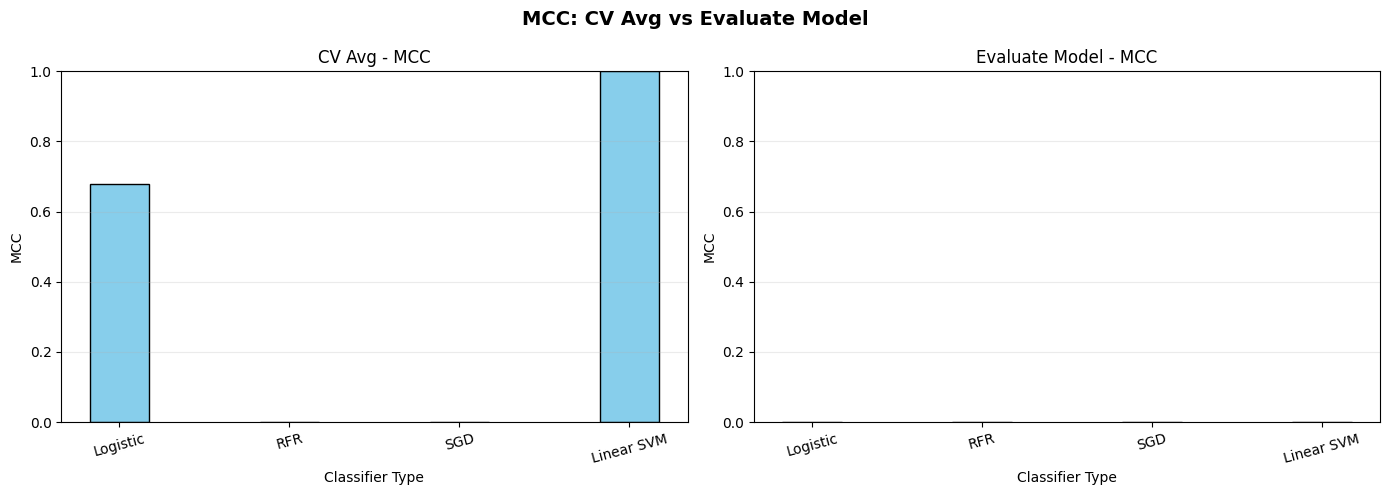

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Define classifiers to display
classifiers = ['Logistic Regression', 'Random Forest', 'SGDClassifier', 'Linear SVM']
categories = ['Logistic', 'RFR', 'SGD', 'Linear SVM']
metric_names = [
    'Accuracy',
    'Precision',
    'Recall',
    'Specificity',
    'F1',
    'ROC AUC',
    'PR AUC',
    'Balanced Accuracy',
    'MCC',
]

def get_first_dict(var_names):
    for var_name in var_names:
        value = globals().get(var_name)
        if isinstance(value, dict):
            return value
    return None

def cv_metric_value(cv_dict, model_name, metric):
    model_result = cv_dict.get(model_name)
    if model_result is None:
        return np.nan
    # Each model entry is a fold-level DataFrame; use mean across folds.
    if hasattr(model_result, 'columns') and metric in model_result.columns:
        return model_result[metric].mean()
    return np.nan

def eval_metric_value(eval_dict, model_name, metric):
    model_result = eval_dict.get(model_name, {})
    return model_result.get(metric, np.nan)

# Use CV-fold results and overall test-set evaluate-model results
cvavg = get_first_dict(['cv_resultsiv'])
overalleval = get_first_dict(['evaluate_modelsiv'])

if cvavg is None or overalleval is None:
    raise ValueError('Missing dictionaries. Expected cv_resultsiv and evaluate_modelsiv.')

for metric in metric_names:
    cvvalues = [cv_metric_value(cvavg, clf, metric) for clf in classifiers]
    overallvalues = [eval_metric_value(overalleval, clf, metric) for clf in classifiers]

    x = np.arange(len(categories))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Panel 1: CV average across folds
    axes[0].bar(x, cvvalues, width, color='skyblue', edgecolor='black')
    axes[0].set_title(f'CV Avg - {metric}')
    axes[0].set_xlabel('Classifier Type')
    axes[0].set_ylabel(metric)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(categories, rotation=15)
    axes[0].grid(axis='y', alpha=0.25)
    axes[0].set_ylim([0, 1])

    # Panel 2: evaluate_model metrics on held-out test set
    axes[1].bar(x, overallvalues, width, color='salmon', edgecolor='black')
    axes[1].set_title(f'Evaluate Model - {metric}')
    axes[1].set_xlabel('Classifier Type')
    axes[1].set_ylabel(metric)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(categories, rotation=15)
    axes[1].grid(axis='y', alpha=0.25)
    axes[1].set_ylim([0, 1])

    fig.suptitle(f'{metric}: CV Avg vs Evaluate Model', fontsize=14, fontweight='bold')
    fig.tight_layout()
    plt.show()